# Experiment: what does the live `avg_value` measure?

**Question (Q1 in `decisions.md`).** The data.gov.in live feed reports `min_value`, `avg_value` and `max_value` for each station. Our training data (Kaggle CPCB) is **hourly**. Is the live `avg_value` also an hourly value, or an average over a longer rolling window — and if so, how long?

**Why it matters.** If live inputs and live "actuals" measure a different quantity from the training target, the model suffers training–serving skew and the monitoring reports false drift. The answer decides design choice Q1 (option B = forecast the 24-hour average).

**Hypotheses.** The live value at hour *t* is the mean of the last **L** hourly values, `A_t = mean(x_{t-L+1}, …, x_t)`, with `min_value` / `max_value` the extremes over the same window.
- **H1:** L = 1 (an hourly value)
- **H24:** L = 24 (CPCB's averaging period for the PM2.5 AQI)
- or some other L.

**Four independent tests**

| Test | Idea | Uses |
|---|---|---|
| 1. Sanity | `min ≤ avg ≤ max` always; how wide is the min–max spread? | live data only |
| 2. Signature matching | Simulate what the feed *would* report for each candidate L from real Kaggle hourly data, and see which L best matches the live statistics | live + Kaggle |
| 3. Bounds on L | Derive a lower and an upper limit for L from the live data alone, with no assumptions about the data's statistics | live data only |
| 4. Same stations, side by side | Plot the same stations' training data (hourly vs 24-h rolling) next to their live readings | live + Kaggle |

The tests rely on different evidence, so if they agree, the conclusion is robust. Run all cells top to bottom (**Run All**); the last cell prints a summary.


## 0. Setup

In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LIVE_DIR = ROOT / "data" / "raw" / "live" / "datagov"
RAW_DIR = ROOT / "data" / "raw" / "cpcb"
PM = "PM2.5 (ug/m3)"

CANDIDATE_WINDOWS = [1, 2, 4, 8, 12, 16, 24, 36, 48]   # hours to test
KAGGLE_FROM_YEAR = 2018    # recent years only: closer to today's monitoring network

cities = list(yaml.safe_load(open(ROOT / "params.yaml"))["data"]["cities"])
print(len(cities), "cities:", ", ".join(cities))

14 cities: Delhi, Lucknow, Patna, Kanpur, Jaipur, Chandigarh, Mumbai, Ahmedabad, Pune, Bengaluru, Chennai, Hyderabad, Kolkata, Guwahati


### Load the live snapshots

Every hourly snapshot is stacked into one table. The same reading can appear in two snapshots (e.g. runs at 16:30 and 17:05 can both catch the 16:00 reading), so each **(station, `last_update`)** pair is kept once. Values arrive as text and are converted to numbers. Columns are renamed to `avg`, `min`, `max` so the live data and the simulated data (Test 2) share one format.

In [2]:
files = sorted(LIVE_DIR.glob("*/*.csv"))
# Keep only the longest stretch of snapshots with no gap longer than 45 min
snap = pd.to_datetime([f"{f.parent.name} {f.stem}" for f in files], format="%Y-%m-%d %H%M")
block = (pd.Series(snap).diff() > pd.Timedelta(minutes=45)).cumsum()
length = pd.Series(snap).groupby(block).agg(lambda s: s.max() - s.min())
keep = length.idxmax()
files = [f for f, b in zip(files, block) if b == keep]
print(f"Using {len(files)} snapshots: {snap[block == keep].min()} to "
      f"{snap[block == keep].max()} UTC (longest continuous stretch)")
live = pd.concat((pd.read_csv(f) for f in files), ignore_index=True)
for col in ["city", "station"]:
    live[col] = live[col].astype(str).str.strip()
live["last_update"] = pd.to_datetime(live["last_update"], format="%d-%m-%Y %H:%M:%S")
for col in ["min_value", "max_value", "avg_value"]:
    live[col] = pd.to_numeric(live[col], errors="coerce")

lv = (live[live["city"].isin(cities)]
      .dropna(subset=["min_value", "max_value", "avg_value"])
      .sort_values("fetched_at_utc")
      .drop_duplicates(["station", "last_update"])
      .rename(columns={"avg_value": "avg", "min_value": "min", "max_value": "max"})
      .sort_values(["station", "last_update"])
      .reset_index(drop=True))

HOURS = lv["last_update"].nunique()
SEASON_MONTHS = sorted(lv["last_update"].dt.month.unique())
print(f"{len(files)} snapshots | {HOURS} distinct reading hours "
      f"({lv['last_update'].min()} to {lv['last_update'].max()} IST)")
print(f"{lv['station'].nunique()} stations in our cities | {len(lv)} station-hours")
print("months covered:", SEASON_MONTHS)
if HOURS < 24:
    print("NOTE: fewer than 24 hours collected; Tests 2 and 3 get stronger with a full day.")

Using 57 snapshots: 2026-10-22 05:35:00 to 2026-10-23 09:35:00 UTC (longest continuous stretch)


/tmp/ipykernel_10296/912423254.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  block = (pd.Series(snap).diff() > pd.Timedelta(minutes=45)).cumsum()


57 snapshots | 28 distinct reading hours (2026-10-22 10:00:00 to 2026-10-23 14:00:00 IST)
156 stations in our cities | 4148 station-hours
months covered: [np.int32(10)]


### Helpers used by several tests

- `consecutive_pairs` attaches each row's **previous-hour** values per station and keeps only pairs exactly **1 hour apart**, so skipped hours (laptop asleep, station offline) never count as one-hour changes.
- `signature` summarises how a min/avg/max series behaves from hour to hour, using four statistics:
  - **median |change of avg|** — rolling averages move slowly, hourly values jump;
  - **% of hours `max` unchanged** and **% `min` unchanged** — an extreme reading stays the window's max/min until it leaves the window, so long windows keep min/max constant for many hours;
  - **median spread ratio** `(max − min) / avg` — a long window contains more varied readings, so its min–max range is wider.

In [3]:
def consecutive_pairs(df: pd.DataFrame, time_col: str, group_col: str) -> pd.DataFrame:
    """Add previous-hour avg/min/max per group; keep only rows exactly 1 h after the previous one."""
    df = df.sort_values([group_col, time_col]).copy()
    g = df.groupby(group_col)
    for col in ["avg", "min", "max"]:
        df[f"prev_{col}"] = g[col].shift()
    df["gap_h"] = g[time_col].diff().dt.total_seconds() / 3600
    return df[df["gap_h"] == 1]


def signature(pairs: pd.DataFrame) -> pd.Series:
    """Hour-to-hour behaviour of a min/avg/max series."""
    return pd.Series({
        "median_abs_change_avg": (pairs["avg"] - pairs["prev_avg"]).abs().median(),
        "pct_max_unchanged": 100 * (pairs["max"] == pairs["prev_max"]).mean(),
        "pct_min_unchanged": 100 * (pairs["min"] == pairs["prev_min"]).mean(),
        "median_spread_ratio": ((pairs["max"] - pairs["min"])
                                / pairs["avg"].where(pairs["avg"] > 0)).median(),
    })


live_pairs = consecutive_pairs(lv, "last_update", "station")
live_sig = signature(live_pairs)
print("consecutive-hour pairs in the live data:", len(live_pairs))
live_sig.round(2)

consecutive-hour pairs in the live data: 3829


median_abs_change_avg     1.00
pct_max_unchanged        90.91
pct_min_unchanged        91.30
median_spread_ratio       1.00
dtype: float64

## Test 1 — Sanity: `min ≤ avg ≤ max`, and how wide is the window?

If the three values describe one window, `avg` must always lie between `min` and `max`.

The **spread** is informative too. Within a single hour PM2.5 varies little, so if `min`/`max` described one hour, `max − min` would usually be small relative to `avg`. Over 24 hours, the night-time peak and afternoon low both fall in the window, so the spread is typically a large fraction of the average.

min <= avg <= max holds for 100.0% of station-hours
spread ratio (max - min) / avg:
count    4148.00
mean        1.07
std         0.56
min         0.00
10%         0.49
50%         1.00
90%         1.66
max         6.11
dtype: float64


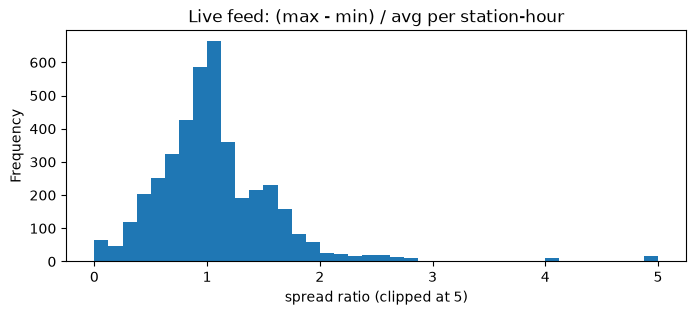

In [4]:
inside = (lv["min"] <= lv["avg"]) & (lv["avg"] <= lv["max"])
spread_ratio = (lv["max"] - lv["min"]) / lv["avg"].where(lv["avg"] > 0)
print(f"min <= avg <= max holds for {100 * inside.mean():.1f}% of station-hours")
print("spread ratio (max - min) / avg:")
print(spread_ratio.describe(percentiles=[0.1, 0.5, 0.9]).round(2))

ax = spread_ratio.clip(upper=5).plot.hist(bins=40, figsize=(8, 3))
ax.set(title="Live feed: (max - min) / avg per station-hour", xlabel="spread ratio (clipped at 5)")
plt.show()

## Test 2 — Signature matching against simulated feeds

**Idea.** Take real hourly PM2.5 from the Kaggle data and *simulate* what the live feed would report if it averaged the last **L** hours, for every candidate L. Compute the same four statistics for each simulated feed and compare them with the live feed. The L whose "fingerprint" is closest is the best explanation.

**Making the comparison fair**
- **Same cities** (our 14) and **same months of the year** as the live data — PM2.5 variability depends strongly on season.
- **Recent years** only (from 2018).
- **Rounded to whole numbers**, like the live feed. Without this, simulated changes of 0.4 would never appear as "unchanged".
- **Minimum data rule:** a window needs about two thirds of its hours (16 of 24, CPCB's rule for the 24-hour AQI), scaled for other window lengths.

**Distance.** For each statistic, the difference between the simulated and live value is divided by that statistic's range across all L (so all four count equally), then summed. Smallest distance = best match.

This cell reads about 150 station files and runs 9 simulations; expect 1–3 minutes.

In [5]:
stations = pd.read_csv(RAW_DIR / "stations_info.csv")
for col in ["city", "station_location"]:
    stations[col] = stations[col].astype(str).str.strip()
sel = stations[stations["city"].isin(cities)]

hourly = {}
for code in sel["file_name"]:
    path = RAW_DIR / f"{code}.csv"
    if not path.exists():
        continue
    df = pd.read_csv(path, usecols=lambda c: c in ("From Date", PM))
    if PM not in df.columns:
        continue
    s = df.set_index(pd.to_datetime(df["From Date"]))[PM]
    s = s[~s.index.duplicated()].sort_index()
    s = s[s.index.year >= KAGGLE_FROM_YEAR]
    if s.notna().sum() < 2000:
        continue
    hourly[code] = s.asfreq("h")          # one row per real hour; gaps become NaN
print(len(hourly), "Kaggle stations loaded")


def simulate(s: pd.Series, L: int) -> pd.DataFrame:
    """What the live feed would report if it averaged the last L hours (rounded like the feed)."""
    r = s.rolling(L, min_periods=max(1, round(L * 16 / 24)))
    out = pd.DataFrame({"avg": r.mean(), "min": r.min(), "max": r.max()}).round()
    return out[out.index.month.isin(SEASON_MONTHS)].dropna()


sig_rows = {}
for L in CANDIDATE_WINDOWS:
    parts = []
    for code, s in hourly.items():
        sim = simulate(s, L)
        sim["station"] = code
        parts.append(sim.rename_axis("time").reset_index())
    sig_rows[L] = signature(consecutive_pairs(pd.concat(parts), "time", "station"))

sig = pd.DataFrame(sig_rows).T
sig.index.name = "window_h"
rng = (sig.max() - sig.min()).replace(0, np.nan)
distance = ((sig - live_sig).abs() / rng).sum(axis=1)
BEST_L = int(distance.idxmin())

comparison = pd.concat([sig.assign(distance=distance), live_sig.to_frame("LIVE").T])
print(f"Best-matching window: {BEST_L} h")
comparison.round(2)

143 Kaggle stations loaded
Best-matching window: 24 h


,median_abs_change_avg,pct_max_unchanged,pct_min_unchanged,median_spread_ratio,distance
1,6.0,7.24,7.24,0.00,3.47
2,4.0,27.17,27.59,0.11,2.59
4,3.0,45.71,46.77,0.32,1.85
8,2.0,64.28,64.40,0.61,1.06
12,2.0,74.79,72.99,0.81,0.70
16,1.0,80.04,78.37,0.96,0.31
24,1.0,87.63,89.03,1.15,0.16
36,1.0,90.19,91.37,1.33,0.23
48,0.0,92.41,93.54,1.47,0.53
LIVE,1.0,90.91,91.30,1.00,NaN


**Reading the plots.** Each panel shows one statistic for every simulated window (line) and the live value (dashed red). Where the curve crosses the dashed line is the window consistent with that statistic. If all four panels cross near the same L, the evidence agrees.

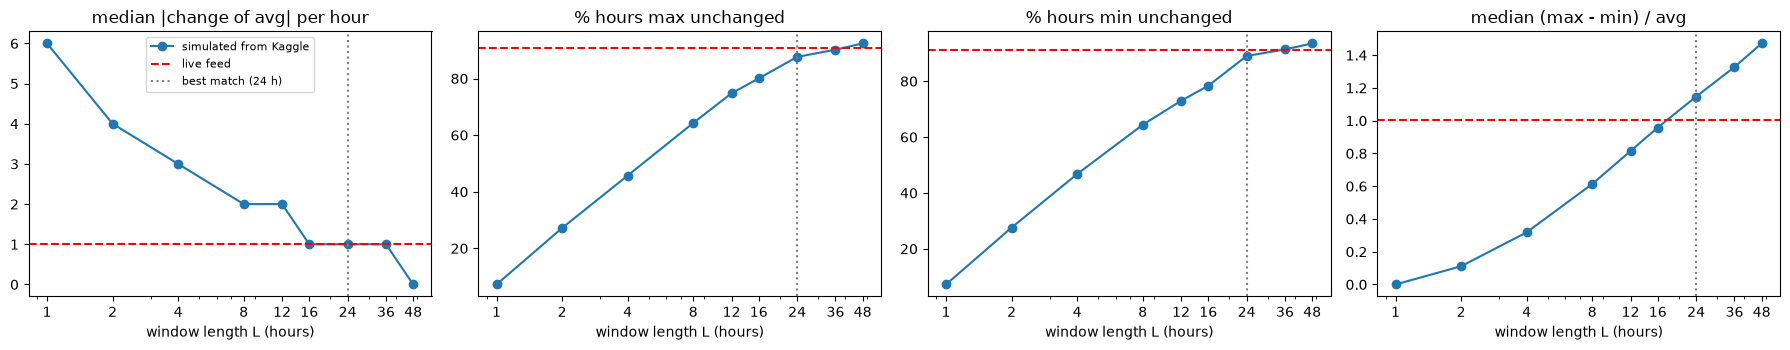

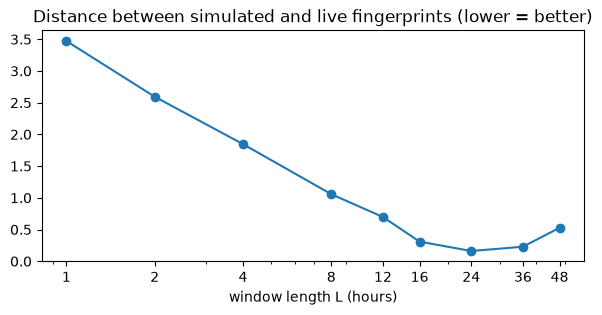

In [6]:
titles = {
    "median_abs_change_avg": "median |change of avg| per hour",
    "pct_max_unchanged": "% hours max unchanged",
    "pct_min_unchanged": "% hours min unchanged",
    "median_spread_ratio": "median (max - min) / avg",
}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, (col, title) in zip(axes, titles.items()):
    ax.plot(sig.index, sig[col], marker="o", label="simulated from Kaggle")
    ax.axhline(live_sig[col], color="red", linestyle="--", label="live feed")
    ax.axvline(BEST_L, color="gray", linestyle=":", label=f"best match ({BEST_L} h)")
    ax.set(title=title, xlabel="window length L (hours)", xscale="log")
    ax.set_xticks(CANDIDATE_WINDOWS)
    ax.set_xticklabels(CANDIDATE_WINDOWS)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

ax = distance.plot(marker="o", figsize=(7, 3), logx=True,
                   title="Distance between simulated and live fingerprints (lower = better)")
ax.set_xticks(CANDIDATE_WINDOWS)
ax.set_xticklabels(CANDIDATE_WINDOWS)
ax.set_xlabel("window length L (hours)")
plt.show()

## Test 3 — Bounds on L from the live data alone

Test 2 depends on how similar 2018–2022 data is to today. This test needs **no other data**: it derives limits on L purely from the live readings.

**Lower bound — how long can an extreme stay?** A reading taken at hour *s* is inside the window for exactly L consecutive hours (*s* … *s*+L−1). So the same reading can be the window's `max` (or `min`) for **at most L hours**. If `max_value` stays unchanged for *r* consecutive hours, then **L ≥ r** — unless two different readings happen to have the same whole-number value, which is uncommon. The longest run across all stations gives the lower bound. *(A run cut short by the start or end of our collection is still a valid lower bound.)*

**Upper bound — how fast can the average move?** For a rolling mean, moving one hour forward adds the newest reading and drops the oldest:

$$A_t - A_{t-1} = \frac{x_t - x_{t-L}}{L}$$

The newest reading is at most the current window max, and the dropped reading was at least the previous window's min, so $x_t - x_{t-L} \le \max_t - \min_{t-1}$. Therefore

$$L \le \frac{\max_t - \min_{t-1}}{A_t - A_{t-1}} \quad (\text{when the average rises}),$$

and symmetrically when it falls. **A large jump in the average with a narrow min–max range forces a short window.**

**Rounding.** Live values are whole numbers, so a true change can differ from the reported change by up to 1. We use only changes of at least 2 and shrink each by 1 (the worst case), and widen the min–max range by 1, so the bound stays valid despite rounding.

**Result.** Any window length consistent with the data must lie between the two bounds. If the interval contains 24 and excludes 1, the 24-hour hypothesis survives and the hourly one is rejected.

In [7]:
runs = lv.sort_values(["station", "last_update"]).copy()
g = runs.groupby("station")
new_segment = g["last_update"].diff().dt.total_seconds().div(3600).ne(1)   # gap or first row
for col in ["max", "min"]:
    run_id = (new_segment | g[col].diff().ne(0)).cumsum()
    runs[f"run_{col}"] = runs.groupby(run_id)[col].transform("size")

longest = runs.groupby(["city", "station"])[["run_max", "run_min"]].max()
LOWER = int(longest.max().max())
print(f"Lower bound: L >= {LOWER} h (longest run of an unchanged max/min)")
print("Stations with the longest runs:")
display(longest.max(axis=1).sort_values(ascending=False).head(8).rename("longest_run_h").to_frame())

p = live_pairs.copy()
dA = p["avg"] - p["prev_avg"]
rise, fall = dA >= 2, dA <= -2
p["L_upper"] = np.nan
p.loc[rise, "L_upper"] = (p["max"] - p["prev_min"] + 1)[rise] / (dA[rise] - 1)
p.loc[fall, "L_upper"] = (p["prev_max"] - p["min"] + 1)[fall] / (-dA[fall] - 1)
events = p.dropna(subset=["L_upper"]).sort_values("L_upper")
UPPER = events["L_upper"].min()
UPPER_ROBUST = events["L_upper"].nsmallest(3).max()   # ignores up to 2 glitchy events
print(f"\nUpper bound: L <= {UPPER:.1f} h from {len(events)} informative hours "
      f"(robust, ignoring the 2 tightest: L <= {UPPER_ROBUST:.1f} h)")
print("Tightest events (inspect these if the bound looks surprising):")
display(events[["city", "station", "last_update", "prev_min", "prev_avg", "prev_max",
                "min", "avg", "max", "L_upper"]].head(5).round(1))

Lower bound: L >= 20 h (longest run of an unchanged max/min)
Stations with the longest runs:


longest_run_h
city      station                                           
Bengaluru Hebbal, Bengaluru - KSPCB                       20
Ahmedabad Rakhial, Ahmedabad - IITM                       20
Delhi     Aya Nagar, Delhi - IITM                         20
Chennai   Velachery Res. Area, Chennai - CPCB             20
          Royapuram, Chennai - TNPCB                      20
Mumbai    Bandra Kurla Complex, Mumbai - MPCB             20
          Borivali East, Mumbai - MPCB                    20
Kolkata   Fort William, Kolkata - WBPCB                   20


Upper bound: L <= 25.9 h from 980 informative hours (robust, ignoring the 2 tightest: L <= 26.1 h)
Tightest events (inspect these if the bound looks surprising):


,city,station,last_update,prev_min,prev_avg,prev_max,min,avg,max,L_upper
3521,Jaipur,"Sector-2 Murlipura, Jaipur - RSPCB",2026-10-23 08:00:00,47.0,75.0,253.0,47.0,66.0,98.0,25.9
2035,Lucknow,"Lalbagh, Lucknow - CPCB",2026-10-22 21:00:00,91.0,231.0,369.0,83.0,219.0,369.0,26.1
2041,Lucknow,"Lalbagh, Lucknow - CPCB",2026-10-23 03:00:00,83.0,189.0,369.0,83.0,177.0,339.0,26.1
1422,Patna,"IGSC Planetarium Complex, Patna - BSPCB",2026-10-23 14:00:00,51.0,74.0,153.0,49.0,69.0,103.0,26.2
2047,Lucknow,"Lalbagh, Lucknow - CPCB",2026-10-23 10:00:00,83.0,146.0,323.0,83.0,136.0,256.0,26.8


## Test 4 — Same stations: training data vs live data

The live stations are matched to their Kaggle counterparts by name (e.g. live `"Alipur, Delhi - DPCC"` ↔ Kaggle `"Alipur, Delhi"`), one station per city for up to six cities.

- **Left:** the station's **training data** from the same month in its most recent year — hourly values (grey dots) with the 24-hour rolling min / mean / max computed from them.
- **Right:** the same station's **live readings**.

If the live lines look like the left panel's **coloured rolling lines** (smooth mean, step-shaped min/max) rather than the **grey hourly dots** (jumpy), the live feed reports rolling statistics. The two panels cover different years, so compare **shapes**, not levels.

111 of 156 live stations matched to a Kaggle station by name


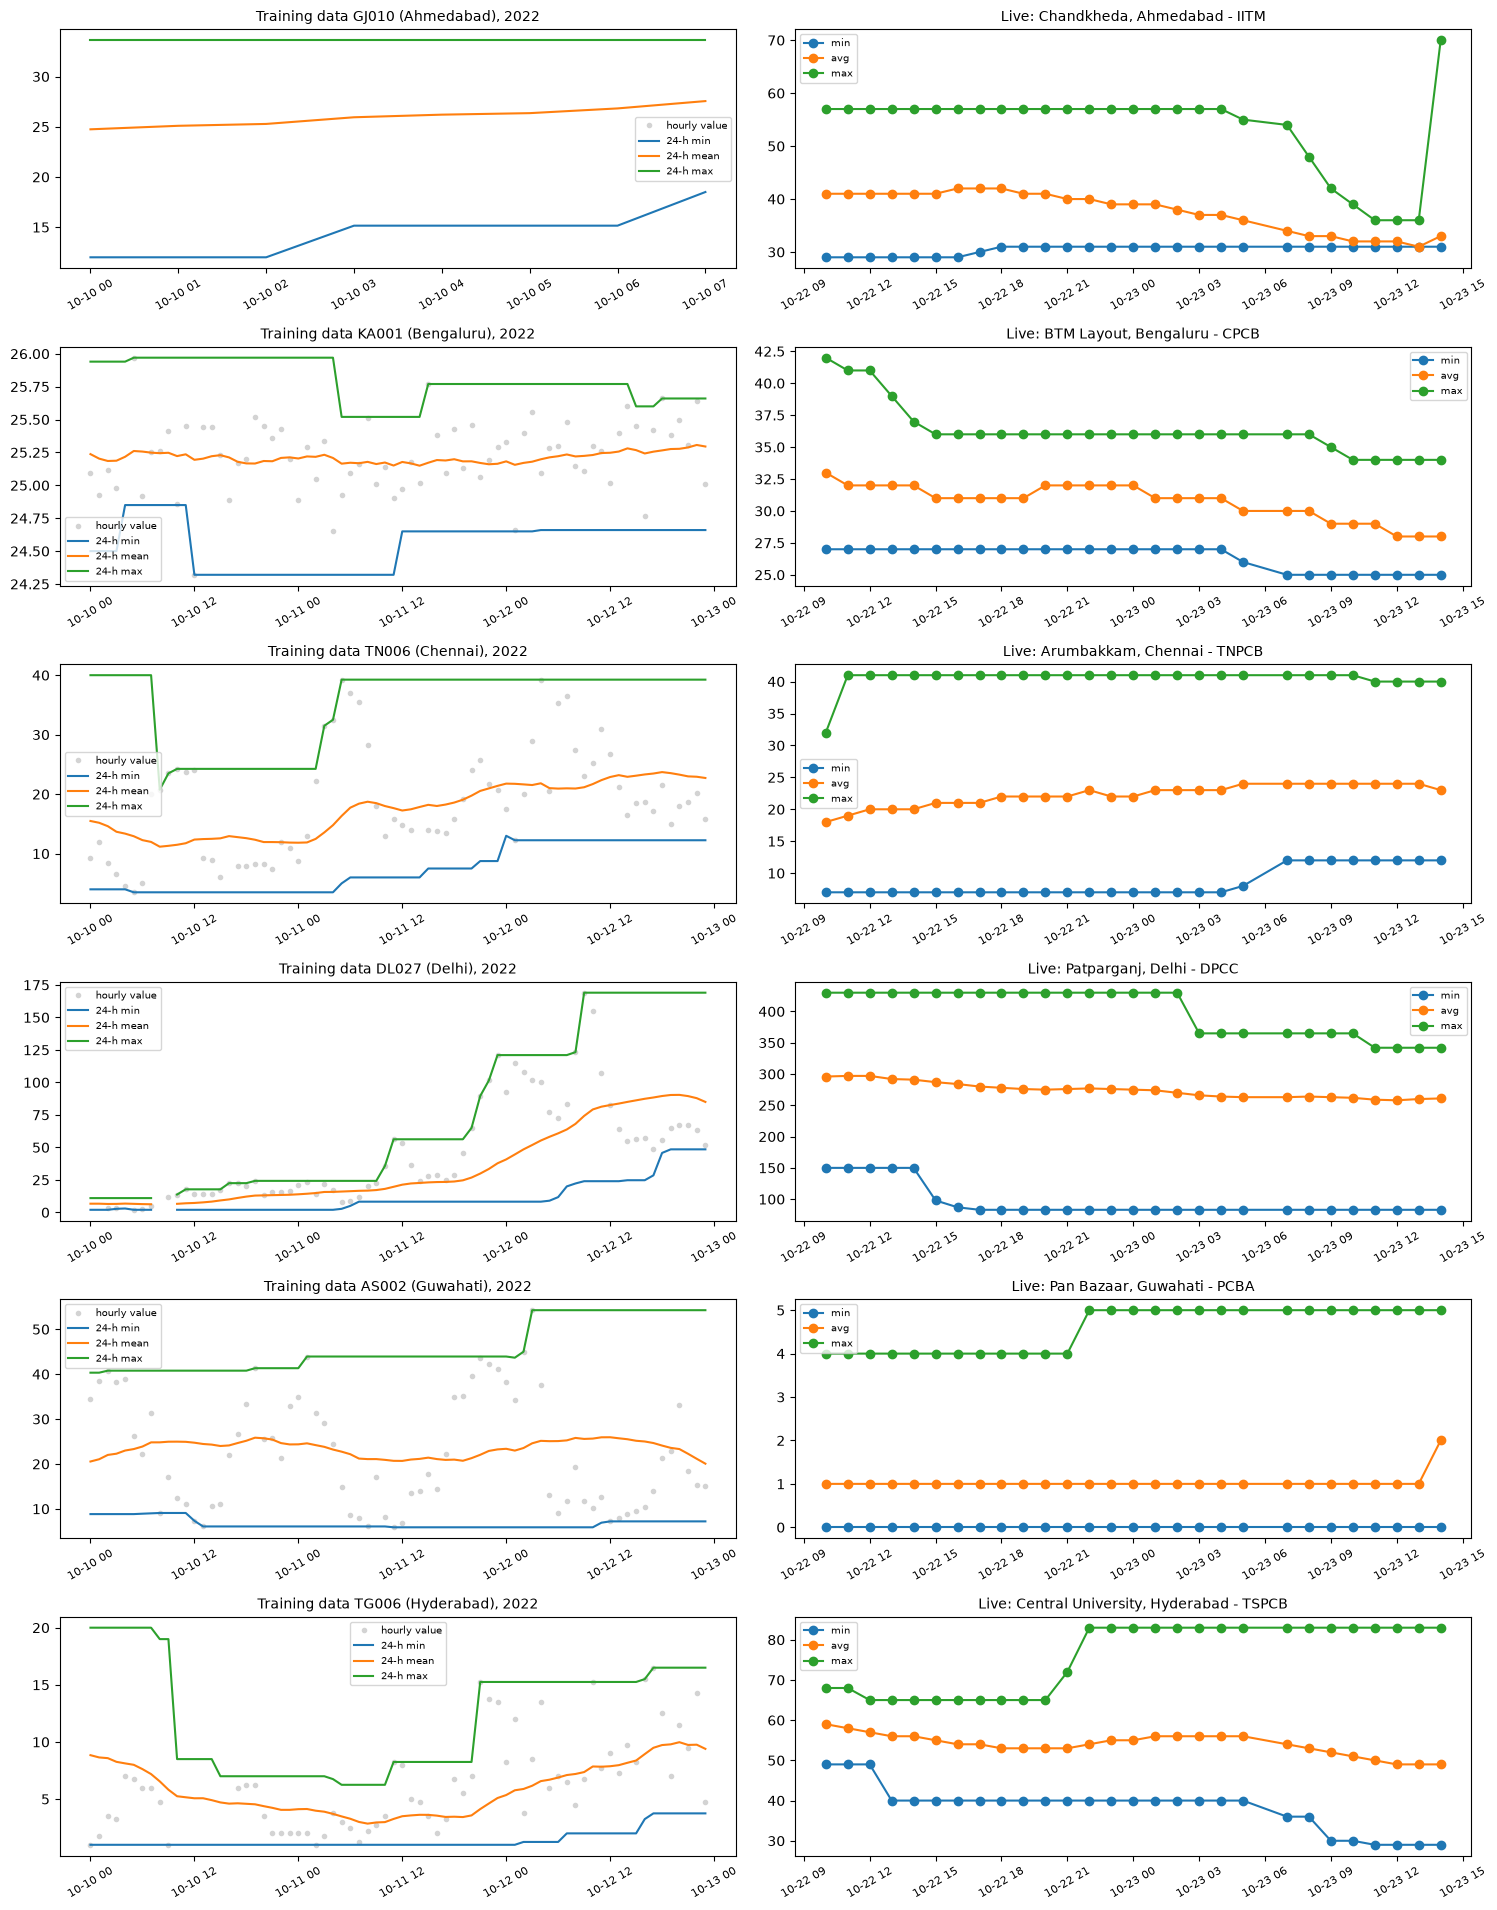

In [8]:
def norm(name: str) -> str:
    """'Alipur, Delhi - DPCC' and 'Alipur, Delhi ' -> 'alipur delhi'."""
    return " ".join(str(name).split(" - ")[0].lower().replace(",", " ").split())


kaggle_by_name = {norm(loc): code for code, loc in zip(sel["file_name"], sel["station_location"])
                  if code in hourly}
per_station = lv.groupby(["city", "station"]).size().rename("hours").reset_index()
per_station["code"] = per_station["station"].map(lambda n: kaggle_by_name.get(norm(n)))
matched = per_station.dropna(subset=["code"]).sort_values("hours", ascending=False)
print(f"{len(matched)} of {len(per_station)} live stations matched to a Kaggle station by name")
picks = matched.drop_duplicates("city").head(6)

month = SEASON_MONTHS[0]
fig, axes = plt.subplots(len(picks), 2, figsize=(15, 3.2 * len(picks)), squeeze=False)
for (ax_k, ax_l), row in zip(axes, picks.itertuples()):
    s = hourly[row.code]
    years = sorted({t.year for t in s.dropna().index if t.month == month}, reverse=True)
    if years:
        start = pd.Timestamp(years[0], month, 10)
        w = s.rolling(24, min_periods=16)
        frame = pd.DataFrame({"hourly value": s, "24-h min": w.min(), "24-h mean": w.mean(),
                              "24-h max": w.max()}).loc[start:].iloc[:72]       # 72 hours
        ax_k.plot(frame.index, frame["hourly value"], ".", color="lightgray", label="hourly value")
        for col in ["24-h min", "24-h mean", "24-h max"]:
            ax_k.plot(frame.index, frame[col], label=col)
        ax_k.set_title(f"Training data {row.code} ({row.city}), {years[0]}", fontsize=10)
        ax_k.legend(fontsize=7)
        ax_k.tick_params(axis="x", labelrotation=30, labelsize=8)
    lsta = lv[lv["station"] == row.station].set_index("last_update")[["min", "avg", "max"]]
    for col in ["min", "avg", "max"]:
        ax_l.plot(lsta.index, lsta[col], marker="o", label=col)
    ax_l.set_title(f"Live: {row.station}", fontsize=10)
    ax_l.legend(fontsize=7)
    ax_l.tick_params(axis="x", labelrotation=30, labelsize=8)
plt.tight_layout()
plt.show()

## Summary

In [9]:
print("=== avg_value experiment: summary ===")
print(f"Data: {HOURS} live hours, {lv['station'].nunique()} stations, {len(hourly)} Kaggle stations")
print(f"Test 1  min <= avg <= max in {100 * inside.mean():.1f}% of rows; "
      f"median spread ratio {live_sig['median_spread_ratio']:.2f}")
print(f"Test 2  best-matching window: {BEST_L} h  "
      f"(distance at 1 h: {distance[1]:.2f}, at 24 h: {distance[24]:.2f}, best: {distance[BEST_L]:.2f})")
print(f"Test 3  L must lie in [{LOWER}, {UPPER:.1f}] h  (robust upper bound {UPPER_ROBUST:.1f} h)")
print(f"        hourly value (L = 1) rejected:       {LOWER > 1}")
print(f"        24-h window inside the bounds:       {LOWER <= 24 <= UPPER_ROBUST}")
print("Test 4  compare the shapes in the side-by-side plots above")

=== avg_value experiment: summary ===
Data: 28 live hours, 156 stations, 143 Kaggle stations
Test 1  min <= avg <= max in 100.0% of rows; median spread ratio 1.00
Test 2  best-matching window: 24 h  (distance at 1 h: 3.47, at 24 h: 0.16, best: 0.16)
Test 3  L must lie in [20, 25.9] h  (robust upper bound 26.1 h)
        hourly value (L = 1) rejected:       True
        24-h window inside the bounds:       True
Test 4  compare the shapes in the side-by-side plots above


## How to conclude

The 24-hour rolling-average hypothesis is **confirmed** if:
1. **Test 1:** `min ≤ avg ≤ max` holds (≈100%) and the spread is wide (median ratio well above what one hour would give).
2. **Test 2:** the best-matching window is **24 h** (or a neighbouring candidate, with 24 h close behind) and **1 h is clearly worst**.
3. **Test 3:** the bounds **exclude 1 h** and **contain 24 h**.
4. **Test 4:** the live lines resemble the coloured rolling lines, not the grey hourly dots.

**How decisive each test is.** This notebook was checked on simulated data where the true window is known to be 24 h, with 17 hours of "live" data: Test 3 gave L ∈ [17, 32] h (correct: contains 24, rejects 1), while Test 2 ranked 36 h first and 24 h a close second. So **Test 3 is the sharpest**; Test 2 reliably separates short windows from long ones but can be off by one candidate with less than a day of data.

If they conflict, inspect the "tightest events" table in Test 3 (a single faulty station can distort a bound) and rerun after more hours are collected.

**Afterwards:** record the result as a decision entry (Q1 → D21) in `decisions.md`, and update the `avg_value` item under "Known issues" in `docs/data_sources.md`.

## Conclusion (23 Oct 2026)

**The live `avg_value` is a 24-hour rolling average.** All three conditions above are met on the gap-free stretch:

| | All data (46 h, 20–23 Oct, with gaps) | Continuous stretch (28 h, 22 Oct 10:00 – 23 Oct 14:00 IST) |
|---|---|---|
| Test 1: `min ≤ avg ≤ max` | 100% (median spread ratio 1.00) | 100% (median spread ratio 1.00) |
| Test 2: best window | **24 h** (distance 0.13; 1 h: 3.44) | **24 h** (distance 0.16; 1 h: 3.47) |
| Test 3: bounds on L | 20–23 h (robust 20–25 h) | **20–25.9 h** (robust 20–26.1 h) |
| 1 h rejected / 24 h inside | yes / robust bound only | yes / **strict bound** |

**Why the continuous stretch is the stronger result.** In the all-data run, the tightest upper-bound events came from 20–21 Oct, around collection gaps, and pushed the strict bound to 23 h. Using only the longest stretch without a gap over 45 minutes (cell 4) removes them, and 24 h then lies inside the strict bound. The lower bound (20 h) is the same in both runs: a window's max can be replaced early by a new, higher reading, so runs of an unchanged max are often shorter than L.

**Decision.** `processing.avg_window_hours` stays **24**; the target, the live inputs and the live "actuals" all measure the same 24-hour average (`decisions.md` D21, Q1 closed; `docs/data_sources.md` Known issues updated).

**Limits.** 28 continuous hours in one month (October); the lower bound would tighten with a longer gap-free stretch, which is not needed for this decision.